# EA3 · Aprendizaje no supervisado: temas en los informes del conflicto armado

## Pregunta de negocio
**¿Qué grandes temas aparecen en los fragmentos de informes sobre el conflicto armado colombiano, para que un centro de memoria histórica organice su archivo en colecciones temáticas y decida qué líneas pedagógicas y de atención a víctimas priorizar?**

- **Quién la necesita:** el equipo de archivo y pedagogía de un centro de memoria histórica (o una ONG de víctimas).
- **Qué decisión apoya:** cómo agrupar miles de documentos en colecciones y a qué temas dedicar primero recursos de pedagogía, investigación y atención.

**¿Por qué este dataset sirve?** La columna `context` contiene fragmentos reales de informes sobre el conflicto: masacres, desplazamiento, desaparición, despojo de tierras, memoria. Nadie les ha puesto una etiqueta de "tema", así que el problema es **no supervisado**: hay que *descubrir* los grupos, no predecir una respuesta conocida.

| Etapa | Qué se hace |
|---|---|
| 1 · Extracción | `HFDatasetLoader` descarga el dataset y lo convierte en DataFrame |
| 2 · Preprocesamiento | validar → limpiar → convertir los textos en números |
| 3 · Entrenamiento | K-means para varios k → elegir k con evidencia → modelo final |
| 4 · Análisis y métricas | silueta, Davies-Bouldin, perfil de cada grupo, gráficas |
| 5 · Resumen y hallazgos | `reportes/EA3_resumen_modelo.txt` y `reportes/HALLAZGOS.md` |

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().resolve()
while ROOT != ROOT.parent and not (ROOT / "src" / "clases_po").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score

from clases_po import (HFDatasetLoader, PreparadorConflicto, STOPWORDS_ES, AgrupadorTextos,
                       ReporteAgrupamiento, lectura_silueta)

PREGUNTA = {
    "pregunta": ("¿Qué grandes temas aparecen en los fragmentos de informes sobre el conflicto armado colombiano, "
                 "para que un centro de memoria histórica organice su archivo en colecciones temáticas y decida "
                 "qué líneas pedagógicas y de atención a víctimas priorizar?"),
    "quien": "el equipo de archivo y pedagogía de un centro de memoria histórica (o una ONG de víctimas)",
    "decision": "cómo agrupar los documentos en colecciones y a qué temas dedicar primero recursos",
}
DATASET = "jdavit/colombian-conflict-SQA"
CONFIG = None
SPLITS = ["train", "test"]
SEMILLA = 42
FIGURAS = Path("figuras")
FIGURAS.mkdir(exist_ok=True)
pd.set_option("display.max_colwidth", 90)

/home/runner/work/Aprendizaje-supervisado-y-no-supervisado/Aprendizaje-supervisado-y-no-supervisado/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Etapa 1 · Extracción
Se cargan los dos *splits* (`train` y `test`) y se unen: en un problema no supervisado no se necesita una parte de prueba, porque no hay respuesta correcta con la cual comparar.

In [2]:
partes = []
for split in SPLITS:
    loader = HFDatasetLoader(dataset_name=DATASET, config=CONFIG, split=split,
                             filename=f"datos/conflicto_{split}.csv")
    parte = loader.load()
    parte["split_origen"] = split
    print(loader.info())
    partes.append(parte)

df_crudo = pd.concat(partes, ignore_index=True)
print("Forma (filas, columnas):", df_crudo.shape)
df_crudo.head()

Generating train split:   0%|          | 0/2895 [00:00<?, ? examples/s]

Generating train split: 100%|██████████| 2895/2895 [00:00<00:00, 299342.03 examples/s]

Generating test split:   0%|          | 0/30 [00:00<?, ? examples/s]

Generating test split: 100%|██████████| 30/30 [00:00<00:00, 14408.46 examples/s]

{'dataset': 'jdavit/colombian-conflict-SQA', 'config': None, 'split': 'train', 'filas': 2895, 'columnas': 5}


{'dataset': 'jdavit/colombian-conflict-SQA', 'config': None, 'split': 'test', 'filas': 30, 'columnas': 5}
Forma (filas, columnas): (2925, 5)


,question,context,answer,generated_by,split_origen
0,¿Cuáles son los hallazgos principales del informe 058-CI-00233 Informe agroarte Colomb...,Los argumentos conforme a los que estimamos necesario realizar actuaciones efectivas d...,El informe destaca la importancia de los espacios de memoria para construir una paz du...,gpt-4o,train
1,"¿Qué dice el informe 058-CI-00233 Informe ""Agroarte Colombia: Red Territorial de la Me...",Si el objetivo es que la memoria histórica de la época en la que se desarrolló el conf...,El informe Agroarte Colombia sugiere que para abordar las causas estructurales del con...,gpt-4o,train
2,"¿Qué iniciativas propone el informe 058-CI-00233 Informe ""Agroarte Colombia: Red Terri...",Reconocer la transcendencia que estos lugares tienen para la consecución de una paz es...,El informe Agroarte Colombia propone la creación de un marco jurídico específico que g...,gpt-4o,train
3,"¿Cuáles son los hallazgos principales del informe 058-CI-00235 ""Fuego en el remanso de...","Este trabajo recopila y analiza las causas, los hechos victimizantes y los impactos qu...","El informe ""Fuego en el remanso de paz"" documenta los impactos del conflicto armado en...",gpt-4o,train
4,¿Qué actores armados hicieron presencia en Titiribí y qué tipo de violencias ejerciero...,"Según el informe 058-CI-00235 ""Fuego en el remanso de paz"" en Titiribí se identificó l...","Los grupos armados que hicieron presencia en Titiribí incluyeron guerrillas (FARC, EPL...",gpt-4o,train


In [3]:
df_crudo.info()
pd.DataFrame([
    ("question", "pregunta sobre un informe", "describe el grupo (no entra al modelo)"),
    ("context", "fragmento del informe", "**texto que se agrupa**"),
    ("answer", "respuesta escrita por una IA", "no se usa: es texto generado, no el informe original"),
    ("generated_by", "IA que respondió", "no se usa"),
], columns=["columna", "qué es", "uso en el modelo"])

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2925 entries, 0 to 2924
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   question      2925 non-null   object
 1   context       2925 non-null   object
 2   answer        2925 non-null   object
 3   generated_by  2925 non-null   object
 4   split_origen  2925 non-null   object
dtypes: object(5)
memory usage: 114.4+ KB


,columna,qué es,uso en el modelo
0,question,pregunta sobre un informe,describe el grupo (no entra al modelo)
1,context,fragmento del informe,**texto que se agrupa**
2,answer,respuesta escrita por una IA,"no se usa: es texto generado, no el informe original"
3,generated_by,IA que respondió,no se usa


## Etapa 2 · Preprocesamiento

### 2.1 Validar antes de confiar

In [4]:
prep = PreparadorConflicto()
calidad = prep.validar(df_crudo)
calidad

,validación,métrica,decisión
0,Completitud · nulos (todas las columnas),0,convertir a vacío y revisar
1,Completitud · question vacía,0,eliminar fila
2,Completitud · answer vacía,0,eliminar fila
3,Completitud · context vacío,11,conservar y marcar tiene_contexto = 0
4,Unicidad · filas duplicadas (question+context+answer),0,eliminar
5,Formato · textos con espacios dobles o en los bordes,4,normalizar espacios
6,Dominio · valores distintos de generated_by,3,convertir a categoría


### 2.2 Limpiar con reglas repetibles

In [5]:
df = prep.enriquecer(prep.limpiar(df_crudo))
registro = prep.tabla_registro
registro

,paso,filas,cambio,por qué
0,datos crudos,2925,0,train + test de Hugging Face
1,espacios normalizados,2925,0,los espacios extra cambian el conteo de palabras y esconden duplicados
2,con pregunta y respuesta,2925,0,sin pregunta o sin respuesta no hay nada que aprender
3,sin duplicados,2925,0,una fila repetida en entrenamiento y prueba sería ver el examen antes
4,generated_by como categoría,2925,0,"es una etiqueta (qué IA respondió), no texto libre"


### 2.3 Elegir el texto y quitar repetidos
Se agrupa la columna `context` porque contiene el texto **original** de los informes (las respuestas las escribió una IA).
- Se quitan los contextos **vacíos**, porque no hay nada que agrupar.
- Se quitan los **repetidos**: varias preguntas comparten el mismo fragmento, y un texto repetido formaría un grupo artificial.

In [6]:
ag = AgrupadorTextos(columna_texto="context", rango_k=range(2, 13), k_minimo_negocio=4,
                     n_componentes=100, max_features=5000, min_df=3, max_df=0.5, ngram_range=(1, 2),
                     stop_words=STOPWORDS_ES, n_init=10, random_state=SEMILLA,
                     directorio_modelos="entrenamiento")
textos = ag.preparar_datos(df)
textos.str.split().str.len().describe().round(1).rename("palabras por fragmento")

[preparar_datos] 2925 filas -> 2914 con texto -> 2883 textos únicos.


count    2883.0
mean       62.0
std        25.9
min         2.0
25%        43.0
50%        57.0
75%        77.0
max       218.0
Name: palabras por fragmento, dtype: float64

### 2.4 De texto a números, y por qué hay que escalar
K-means agrupa por **distancia**, así que la escala importa: sin cuidado, un texto largo quedaría "lejos" de todos solo por ser largo.

| Paso | Qué hace | Problema que resuelve |
|---|---|---|
| **TF-IDF** | da un peso a cada palabra: alto si es frecuente en ese texto y rara en los demás | convierte el texto en números y resta peso a palabras comunes como "conflicto" o "armado" |
| `max_df=0.5` | ignora palabras que aparecen en más de la mitad de los textos | no ayudan a separar temas |
| `min_df=3` | ignora palabras que aparecen en menos de 3 textos | errores de tipeo y nombres sueltos |
| **SVD** (100 dimensiones) | resume miles de columnas en 100 "ejes de tema" | quita ruido y hace más estables las distancias |
| **Normalizer** | deja cada texto con largo 1 | la distancia mide diferencia de **contenido**, no de tamaño |

Estos pasos aprenden de los datos (vocabulario y ejes de SVD). Como no hay conjunto de prueba en un problema no supervisado, se ajustan con todos los textos.

In [7]:
X = ag.vectorizar(textos)
tfidf = ag.vectorizador.named_steps["tfidf"].transform(textos)
pd.DataFrame({
    "antes (texto)": [f"{len(textos)} textos", "texto libre", "-", "-"],
    "TF-IDF": [f"{tfidf.shape[0]} x {tfidf.shape[1]}", "números", f"{1 - tfidf.nnz / np.prod(tfidf.shape):.1%} ceros", "-"],
    "SVD + normalizar": [f"{X.shape[0]} x {X.shape[1]}", "números", "0 % ceros",
                         f"largo de cada vector = {np.linalg.norm(X, axis=1).mean():.2f}"],
}, index=["forma", "tipo", "matriz vacía", "escala"])

[vectorizar] vocabulario=5000 términos -> 100 dimensiones SVD (conservan 22.2% de la variación).


,antes (texto),TF-IDF,SVD + normalizar
forma,2883 textos,2883 x 5000,2883 x 100
tipo,texto libre,números,números
matriz vacía,-,99.2% ceros,0 % ceros
escala,-,-,largo de cada vector = 1.00


## Etapa 3 · Entrenamiento

### ¿Cómo funciona K-means? (paso a paso)
1. Se elige **k**, el número de grupos.
2. Se ubican k **centroides** iniciales (con `k-means++`, que los reparte lejos entre sí).
3. Cada texto se asigna al **centroide más cercano**.
4. Cada centroide se **recalcula** como el promedio de los textos de su grupo.
5. Se repiten los pasos 3 y 4 hasta que los grupos dejan de cambiar.
6. Como el resultado depende del punto de partida, `n_init=10` lo intenta 10 veces y se queda con la mejor opción (la de menor inercia).

**Inercia** = Σ (distancia de cada texto a su centroide)². K-means busca que sea lo más pequeña posible.

### 3.1 Probar varios k
- **Inercia:** baja siempre al aumentar k. Se busca el "codo", donde deja de bajar mucho.
- **Silueta:** va de -1 a 1. Cerca de 1, cada texto está bien metido en su grupo; cerca de 0, está en la frontera.
- **Davies-Bouldin:** más bajo es mejor.
- **Calinski-Harabasz:** más alto es mejor.

In [8]:
tabla_k = ag.evaluar_k()
tabla_k.round(3)

[evaluar_k] se compararon k = 2 … 12.


,inercia,silueta,Davies-Bouldin,Calinski-Harabasz,grupo más pequeño
k,,,,,
2,2491.926,0.031,3.333,111.269,404
3,2432.736,0.034,5.100,92.004,376
4,2384.115,0.039,4.922,82.136,365
5,2344.416,0.039,4.709,74.807,354
6,2308.214,0.041,4.431,69.788,242
7,2281.944,0.044,4.337,64.324,234
8,2251.594,0.047,4.182,61.394,223
9,2231.159,0.048,4.306,57.484,214
10,2211.943,0.048,4.225,54.296,157


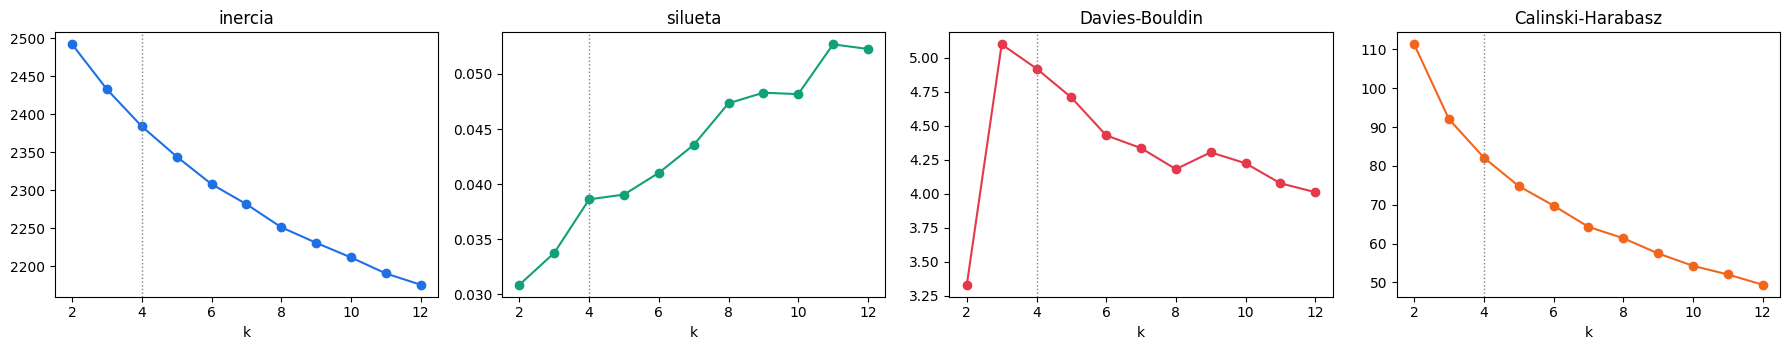

In [9]:
fig, ejes = plt.subplots(1, 4, figsize=(18, 3.6))
for eje, col, color in zip(ejes, ["inercia", "silueta", "Davies-Bouldin", "Calinski-Harabasz"],
                           ["#1f6fe5", "#10a179", "#e5384b", "#f2661b"]):
    eje.plot(tabla_k.index, tabla_k[col], "o-", color=color)
    eje.axvline(ag.k_minimo_negocio, color="gray", ls=":", lw=1)
    eje.set_title(col)
    eje.set_xlabel("k")
plt.tight_layout()
plt.savefig(FIGURAS / "eleccion_k.png", dpi=110)
plt.show()

### 3.2 Elegir k con una regla clara
**Regla:** entre los k que sirven al negocio (**k ≥ 4**: con 2 o 3 grupos no se organiza un archivo), se elige el de **mayor silueta**. Si dos valores casi empatan, gana el k más pequeño, porque menos colecciones son más fáciles de gestionar.

In [10]:
k_elegido = ag.elegir_k()
modelo = ag.entrenar(k_elegido)
pd.Series(ag.metricas).round(4)

[elegir_k] k elegido = 9 (silueta 0.048).


[entrenar] K-means k=9; silueta=0.048; modelo guardado en entrenamiento/20261109_034947_394880_KMeans_k9.pkl


inercia              2231.1590
silueta                 0.0483
davies_bouldin          4.3058
calinski_harabasz      57.4837
dtype: float64

### 3.3 Escenarios: ¿la decisión de k y del preprocesamiento importa?

In [11]:
def silueta_de(etiquetas, espacio):
    return silhouette_score(espacio, etiquetas, random_state=SEMILLA)

tfidf_norm = tfidf  # TF-IDF ya viene con largo 1 por texto, pero sin SVD
sin_svd = KMeans(n_clusters=ag.k, n_init=10, random_state=SEMILLA).fit(tfidf_norm)
escenarios = pd.DataFrame([
    {"escenario": "1 · k = 2", "silueta": tabla_k.loc[2, "silueta"], "Davies-Bouldin": tabla_k.loc[2, "Davies-Bouldin"]},
    {"escenario": f"2 · k = {tabla_k.index.max()}", "silueta": tabla_k["silueta"].iloc[-1],
     "Davies-Bouldin": tabla_k["Davies-Bouldin"].iloc[-1]},
    {"escenario": f"3 · k elegido = {ag.k} (TF-IDF + SVD)", "silueta": ag.metricas["silueta"],
     "Davies-Bouldin": ag.metricas["davies_bouldin"]},
    {"escenario": f"4 · k = {ag.k} sin SVD (solo TF-IDF)", "silueta": silueta_de(sin_svd.labels_, tfidf_norm),
     "Davies-Bouldin": np.nan},
]).set_index("escenario")
escenarios.round(4)

,silueta,Davies-Bouldin
escenario,,
1 · k = 2,0.0309,3.3329
2 · k = 12,0.0523,4.0130
3 · k elegido = 9 (TF-IDF + SVD),0.0483,4.3058
4 · k = 9 sin SVD (solo TF-IDF),0.0062,NaN


## Etapa 4 · Análisis y métricas

### 4.1 Perfil de cada grupo
Para cada grupo se muestra su tamaño, su largo promedio, qué tan apretados están sus textos (cohesión) y las palabras más importantes de su centroide. El nombre de cada grupo se arma automáticamente con sus 3 palabras más fuertes.

In [12]:
perfil = ag.perfil()
perfil

,grupo,nombre,textos,% del total,palabras promedio,cohesión (dist. media al centro),palabras clave
0,6,"G6 · source, farc, violencia",485,16.8,54.0,0.938,"source, farc, violencia, paramilitares, conflicto, grupos, estado, seguridad"
1,0,"G0 · humanos, derechos humanos, derechos",366,12.7,76.8,0.862,"humanos, derechos humanos, derechos, violaciones, violaciones derechos, conflicto, arm..."
2,2,"G2 · armados, grupos, grupos armados",358,12.4,64.1,0.880,"armados, grupos, grupos armados, ilegales, armados ilegales, amenazas, desplazamiento,..."
3,3,"G3 · source, paz, victimas",358,12.4,62.4,0.918,"source, paz, victimas, conflicto, memoria, reparacion, mujeres, verdad"
4,7,"G7 · estructurales, causas, causas estructurales",340,11.8,78.2,0.781,"estructurales, causas, causas estructurales, estructurales conflicto, repeticion, soci..."
5,8,"G8 · ci, pdf, 365",266,9.2,45.0,0.891,"ci, pdf, 365, 365 ci, 1306, 1306 ci, conflicto, violencia"
6,5,"G5 · desaparicion, familiares, testimonios",255,8.8,65.2,0.909,"desaparicion, familiares, testimonios, desaparicion forzada, forzada, victimas, famili..."
7,4,"G4 · 119, 119 ci, ci",241,8.4,47.8,0.845,"119, 119 ci, ci, pdf, tierras, conflicto, comunidades, violencia"
8,1,"G1 · sexual, violencia sexual, violencia",214,7.4,57.9,0.822,"sexual, violencia sexual, violencia, mujeres, victimas, armados, testimonios, victimas..."


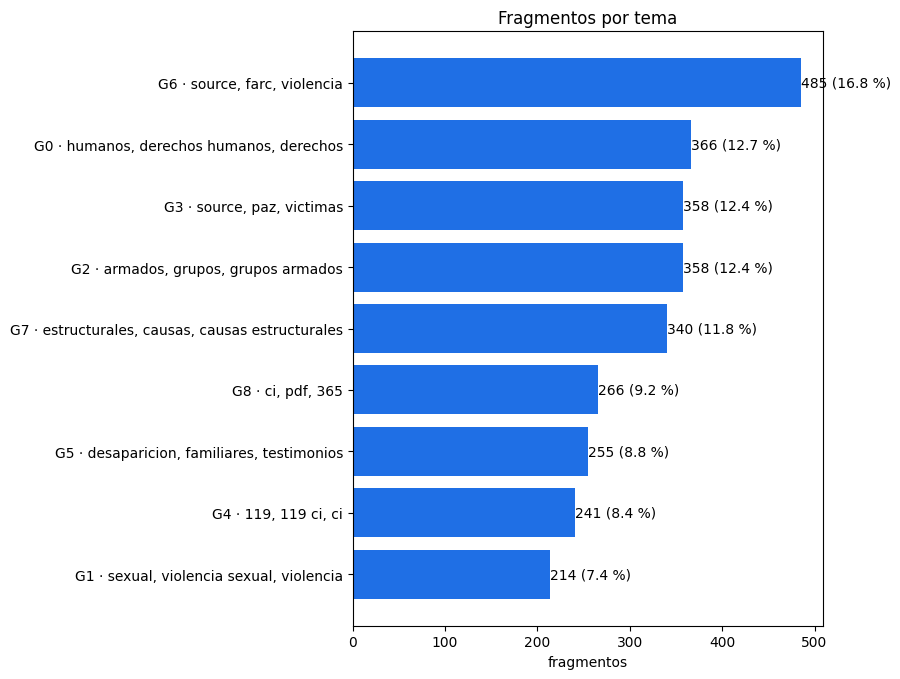

In [13]:
fig, ax = plt.subplots(figsize=(9, 0.6 * ag.k + 1.5))
orden = perfil.sort_values("textos")
ax.barh(orden["nombre"], orden["textos"], color="#1f6fe5")
ax.bar_label(ax.containers[0], labels=[f"{t} ({p} %)" for t, p in zip(orden["textos"], orden["% del total"])])
ax.set_title("Fragmentos por tema")
ax.set_xlabel("fragmentos")
plt.tight_layout()
plt.savefig(FIGURAS / "tamano_grupos.png", dpi=110)
plt.show()

### 4.2 Mapa de los temas
Los 100 ejes no se pueden dibujar, así que PCA los resume en 2 solo para verlos. Puntos cercanos son textos parecidos y cada color es un grupo. Que haya zonas mezcladas es normal: un informe toca varios temas a la vez.

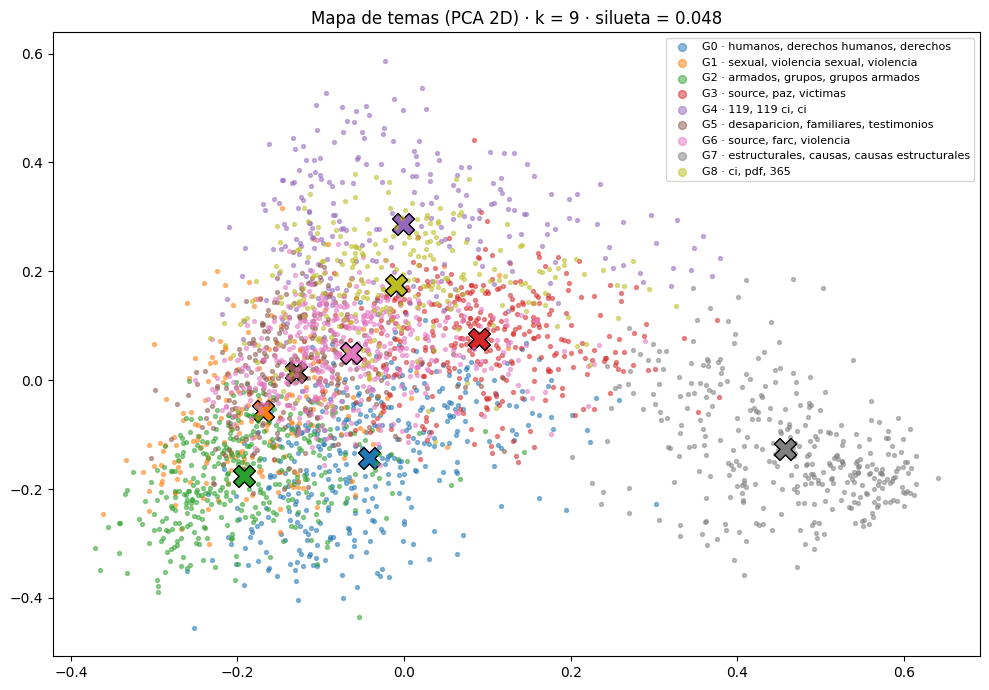

In [14]:
pca = PCA(n_components=2, random_state=SEMILLA)
coords = pca.fit_transform(X)
centros = pca.transform(ag.modelo.cluster_centers_)
nombres = ag.nombres_grupos()

fig, ax = plt.subplots(figsize=(10, 7))
paleta = plt.get_cmap("tab10" if ag.k <= 10 else "tab20")
for g in range(ag.k):
    sel = ag.etiquetas == g
    ax.scatter(coords[sel, 0], coords[sel, 1], s=8, alpha=0.5, color=paleta(g), label=nombres[g])
    ax.scatter(*centros[g], s=250, marker="X", color=paleta(g), edgecolor="black")
ax.set_title(f"Mapa de temas (PCA 2D) · k = {ag.k} · silueta = {ag.metricas['silueta']:.3f}")
ax.legend(fontsize=8, markerscale=2, loc="best")
plt.tight_layout()
plt.savefig(FIGURAS / "mapa_grupos.png", dpi=110)
plt.show()

### 4.3 Textos típicos de cada grupo (los más cercanos al centro)

In [15]:
ag.ejemplos(2)

,grupo,texto típico
0,0,El informe señala que la Armada de Colombia experimentó profundas transformaciones ins...
1,0,"El informe 748-CI-00560 'Banderas rojas en vuelo libertario', entregado a la Comisión ..."
2,1,Los testimonios recopilados reflejan que la violencia sexual fue utilizada de manera s...
3,1,El informe incluye relatos sobre violencia sexual cometida por grupos armados ilegales...
4,2,El informe describe que el desplazamiento forzado en el Bajo Cauca se ha dado tanto de...
5,2,"Según los testimonios recogidos en el informe, la principal motivación para migrar y s..."
6,3,"Desde su fundación, CODHES se ha propuesto contribuir en todas las iniciativas que per..."
7,3,"Las mujeres defensoras han implementado procesos de pedagogía de paz, documentado caso..."
8,4,Informe 119-CI-00339…
9,4,"El informe refiere la presentación de 31 masacres en Boyacá desde 1981, lo cual reflej..."


### 4.4 ¿Qué tipo de preguntas se hacen sobre cada tema?
La pregunta no entró al modelo. Aquí solo se usa para **describir** los grupos después de formarlos.

In [16]:
asignado = df.merge(ag.asignaciones(), on="context", how="inner")
tipos_por_grupo = pd.crosstab(asignado["grupo"].map(nombres), asignado["tipo_pregunta"], normalize="index") * 100
tipos_por_grupo.round(1)

tipo_pregunta,causas_y_recomendaciones,hallazgos,hechos_especificos
grupo,,,
"G0 · humanos, derechos humanos, derechos",7.4,61.2,31.4
"G1 · sexual, violencia sexual, violencia",0.0,20.1,79.9
"G2 · armados, grupos, grupos armados",1.1,16.5,82.4
"G3 · source, paz, victimas",23.1,25.6,51.3
"G4 · 119, 119 ci, ci",17.4,17.4,65.2
"G5 · desaparicion, familiares, testimonios",2.4,13.3,84.3
"G6 · source, farc, violencia",7.8,18.2,73.9
"G7 · estructurales, causas, causas estructurales",99.1,0.6,0.3
"G8 · ci, pdf, 365",17.8,14.9,67.4


### 4.5 Lectura de resultados

In [17]:
m = ag.metricas
print(f"• k = {ag.k} temas. Silueta = {m['silueta']:.3f}: {lectura_silueta(m['silueta'])}.")
print(f"• Davies-Bouldin = {m['davies_bouldin']:.2f} (en k = 2 era {tabla_k.loc[2, 'Davies-Bouldin']:.2f}; más bajo es mejor).")
print(f"• Tema más grande: {perfil.iloc[0]['nombre']} ({perfil.iloc[0]['% del total']} %). "
      f"Más pequeño: {perfil.iloc[-1]['nombre']} ({perfil.iloc[-1]['% del total']} %).")
print(f"• Con SVD la silueta es {m['silueta']:.3f}; sin SVD, {escenarios.iloc[3]['silueta']:.3f}: "
      + ("resumir con SVD ayudó a separar mejor." if m['silueta'] > escenarios.iloc[3]['silueta'] else
         "en este caso SVD no mejoró la separación, pero reduce el ruido y el tiempo de cálculo."))

• k = 9 temas. Silueta = 0.048: grupos débiles: muchos textos están en la frontera entre dos temas.
• Davies-Bouldin = 4.31 (en k = 2 era 3.33; más bajo es mejor).
• Tema más grande: G6 · source, farc, violencia (16.8 %). Más pequeño: G1 · sexual, violencia sexual, violencia (7.4 %).
• Con SVD la silueta es 0.048; sin SVD, 0.006: resumir con SVD ayudó a separar mejor.


## Etapa 5 · Resumen automático y documento de hallazgos

In [18]:
reporte = ReporteAgrupamiento(PREGUNTA, {"dataset": DATASET, "config": CONFIG, "splits": SPLITS},
                              df_crudo, calidad, registro, ag, tipos_por_grupo)
ruta_txt = reporte.resumen_txt("reportes/EA3_resumen_modelo.txt")
ruta_md = reporte.hallazgos_md("reportes/HALLAZGOS.md")
print(ruta_txt.read_text(encoding="utf-8"))

[resumen_txt] guardado en reportes/EA3_resumen_modelo.txt
[hallazgos_md] guardado en reportes/HALLAZGOS.md
RESUMEN AUTOMÁTICO · EA3 Aprendizaje no supervisado (K-means)
Fecha de ejecución: 2026-11-08 22:49:48 (hora de Colombia) · scikit-learn 1.9.1

1. PREGUNTA DE NEGOCIO
------------------------------------------------------------------------------
¿Qué grandes temas aparecen en los fragmentos de informes sobre el conflicto armado colombiano, para que un centro de memoria histórica organice su archivo en colecciones temáticas y decida qué líneas pedagógicas y de atención a víctimas priorizar?
Quién la necesita: el equipo de archivo y pedagogía de un centro de memoria histórica (o una ONG de víctimas)
Qué decisión apoya: cómo agrupar los documentos en colecciones y a qué temas dedicar primero recursos

2. DATASET
------------------------------------------------------------------------------
Identificador: jdavit/colombian-conflict-SQA
Enlace: https://huggingface.co/datasets/jdavit/colo

In [19]:
from IPython.display import Markdown
Markdown(ruta_md.read_text(encoding="utf-8").replace("../figuras/", "figuras/"))

# Documento de hallazgos · EA3

_Generado automáticamente el 2026-11-08 22:49 (hora de Colombia) a partir de la ejecución del notebook._

## Pregunta de negocio
**¿Qué grandes temas aparecen en los fragmentos de informes sobre el conflicto armado colombiano, para que un centro de memoria histórica organice su archivo en colecciones temáticas y decida qué líneas pedagógicas y de atención a víctimas priorizar?**

- **Quién la necesita:** el equipo de archivo y pedagogía de un centro de memoria histórica (o una ONG de víctimas)
- **Qué decisión apoya:** cómo agrupar los documentos en colecciones y a qué temas dedicar primero recursos

## Respuesta corta
Los 2,883 fragmentos de informes se organizan en **9 grandes temas**.
Los tres más frecuentes reúnen el **42 %** del archivo:
**G6 · source, farc, violencia** (16.8 %), **G0 · humanos, derechos humanos, derechos** (12.7 %), **G2 · armados, grupos, grupos armados** (12.4 %).

| Tema (nombre automático) | Fragmentos | Palabras que lo definen |
|---|---|---|
| G6 · source, farc, violencia | 485 (16.8 %) | source, farc, violencia, paramilitares, conflicto, grupos, estado, seguridad |
| G0 · humanos, derechos humanos, derechos | 366 (12.7 %) | humanos, derechos humanos, derechos, violaciones, violaciones derechos, conflicto, armado, conflicto armado |
| G2 · armados, grupos, grupos armados | 358 (12.4 %) | armados, grupos, grupos armados, ilegales, armados ilegales, amenazas, desplazamiento, forzado |
| G3 · source, paz, victimas | 358 (12.4 %) | source, paz, victimas, conflicto, memoria, reparacion, mujeres, verdad |
| G7 · estructurales, causas, causas estructurales | 340 (11.8 %) | estructurales, causas, causas estructurales, estructurales conflicto, repeticion, social, conflicto, exclusion |
| G8 · ci, pdf, 365 | 266 (9.2 %) | ci, pdf, 365, 365 ci, 1306, 1306 ci, conflicto, violencia |
| G5 · desaparicion, familiares, testimonios | 255 (8.8 %) | desaparicion, familiares, testimonios, desaparicion forzada, forzada, victimas, familias, casos |
| G4 · 119, 119 ci, ci | 241 (8.4 %) | 119, 119 ci, ci, pdf, tierras, conflicto, comunidades, violencia |
| G1 · sexual, violencia sexual, violencia | 214 (7.4 %) | sexual, violencia sexual, violencia, mujeres, victimas, armados, testimonios, victimas violencia |

Los nombres salen de las palabras más importantes de cada grupo. El equipo de archivo debe revisarlos y ponerles un nombre definitivo.

## Hallazgos principales
1. **Temas dominantes.** El tema más grande (G6 · source, farc, violencia) concentra el 16.8 % de los fragmentos, y el más pequeño (G1 · sexual, violencia sexual, violencia) el 7.4 %. El archivo no está repartido por igual: unos temas tienen mucho más material que otros.
2. **¿Cuántos temas?** Se probaron de 2 a 12 grupos. Con 9 se obtuvo la mejor separación entre las opciones útiles para organizar un archivo (silueta 0.048).
3. **Textos típicos de cada tema** (los más cercanos al centro del grupo):
- **G0:** _El informe señala que la Armada de Colombia experimentó profundas transformaciones institucionales en respuesta a los desafíos derivados del conflicto armado interno. Entre los hallazgos principales se destaca la adaptac…_
- **G1:** _Los testimonios recopilados reflejan que la violencia sexual fue utilizada de manera sistemática por actores armados como mecanismo de control, castigo y dominación sobre las mujeres. Se registraron casos de violación, a…_
- **G2:** _El informe describe que el desplazamiento forzado en el Bajo Cauca se ha dado tanto de forma masiva como de manera silenciosa y fragmentada. Las amenazas directas, la presencia de grupos armados ilegales y la violencia s…_
- **G3:** _Desde su fundación, CODHES se ha propuesto contribuir en todas las iniciativas que permitan el cierre del conflicto armado y la construcción de una paz sostenible. Su enfoque ha sido buscar la paz como principio estructu…_
- **G4:** _Informe 119-CI-00339…_
- **G5:** _Entre 1998 y 2005, el informe registra varios casos de desaparición forzada en Usme. Destaca el caso de la familia Muñoz, cuyo hijo adolescente fue desaparecido en octubre de 2002 tras haber sido presuntamente señalado d…_
- **G6:** _En Caicedo, la FARC utilizó el territorio para control y desplazamiento, imponiendo conductas a la población y exacciones forzosas. Durante la década de 1990, las AUC realizaron incursiones desde Santa Fe, formando grupo…_
- **G7:** _El informe identifica como causas estructurales del conflicto armado factores como la desigualdad socioeconómica, la ausencia efectiva del Estado, la exclusión de sectores vulnerables y la falta de acceso a servicios bás…_
- **G8:** _Hoy en día Puerto Gaitán se caracteriza por una economía de enclave basada principalmente en la industria petrolera【4:7†365-CI-00931.pdf】.…_

![Elección de k](figuras/eleccion_k.png)
![Mapa de temas](figuras/mapa_grupos.png)
![Tamaño de los temas](figuras/tamano_grupos.png)

## ¿Qué tan confiables son los resultados?
- **Silueta = 0.048** (va de -1 a 1): grupos débiles: muchos textos están en la frontera entre dos temas. En textos es normal que la silueta sea baja: un mismo informe habla de varios temas a la vez (por ejemplo, desplazamiento **y** despojo de tierras), así que muchos fragmentos quedan cerca de la frontera entre dos grupos.
- **Davies-Bouldin = 4.31:** más bajo es mejor. Sirve para comparar entre valores de k, no tiene un umbral absoluto.
- Los grupos se describen con palabras clave y ejemplos que una persona puede revisar, así que la agrupación es **verificable**.
- **Limitaciones:**
  - K-means asigna cada texto a **un solo** tema, aunque en la realidad tenga varios.
  - Supone grupos de forma "redonda" y de tamaño parecido.
  - TF-IDF cuenta palabras, pero no entiende su significado: dos fragmentos que dicen lo mismo con palabras distintas pueden quedar separados.
  - Los fragmentos son extractos cortos y el dataset no cubre todos los informes existentes.

## Recomendaciones
1. **G6 · source, farc, violencia** (16.8 % del archivo): crear una colección temática con sus 485 fragmentos y usar sus textos típicos como punto de partida de una guía pedagógica o de una ruta de consulta para víctimas e investigadores.
2. **G0 · humanos, derechos humanos, derechos** (12.7 % del archivo): crear una colección temática con sus 366 fragmentos y usar sus textos típicos como punto de partida de una guía pedagógica o de una ruta de consulta para víctimas e investigadores.
3. **G2 · armados, grupos, grupos armados** (12.4 % del archivo): crear una colección temática con sus 358 fragmentos y usar sus textos típicos como punto de partida de una guía pedagógica o de una ruta de consulta para víctimas e investigadores.
4. Hacer que un equipo humano **revise una muestra de cada grupo** antes de publicar las colecciones, y ajuste los nombres y los textos mal ubicados.
5. Usar el modelo guardado (`.pkl`) para **clasificar automáticamente los fragmentos nuevos** en el tema más cercano a medida que crezca el archivo, y volver a entrenarlo cuando se agreguen muchos documentos.
6. Priorizar las líneas pedagógicas y de atención en los temas más grandes, sin descuidar los pequeños: pueden representar hechos menos documentados que merecen más investigación.
